<a href="https://colab.research.google.com/github/spicy-peppers84/spicy-peppers84.github.io/blob/main/activity_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

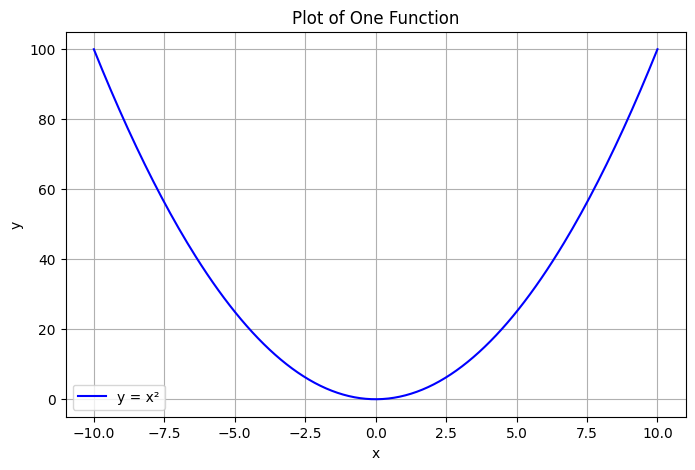

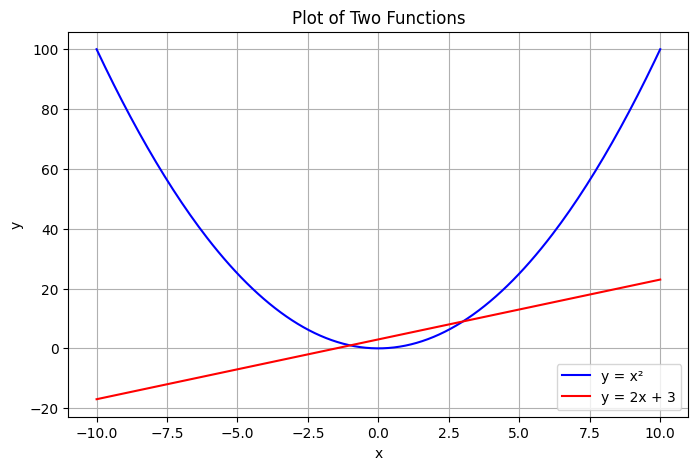

Excel DataFrame:


,chromosomes,basepais(bp)
0,1,248956422
1,2,242193529
2,3,198295559
3,4,190214555
4,5,181538259



Column names:
['chromosomes', 'basepais(bp)']

GENOME SIZE RESULTS
Total base pairs: 3,070,535,648
Total genome size: 3,070.54 Mbp
Total DNA length: 1.0440 meters

WHOLE-GENOME SEQUENCING COSTS


,Year,Cost_per_Mbp_USD,Total_Genome_Cost_USD
0,2001,10000.00,30705356.48
1,2010,1.00,3070.54
2,2011,0.10,307.05
3,2020,0.01,30.71


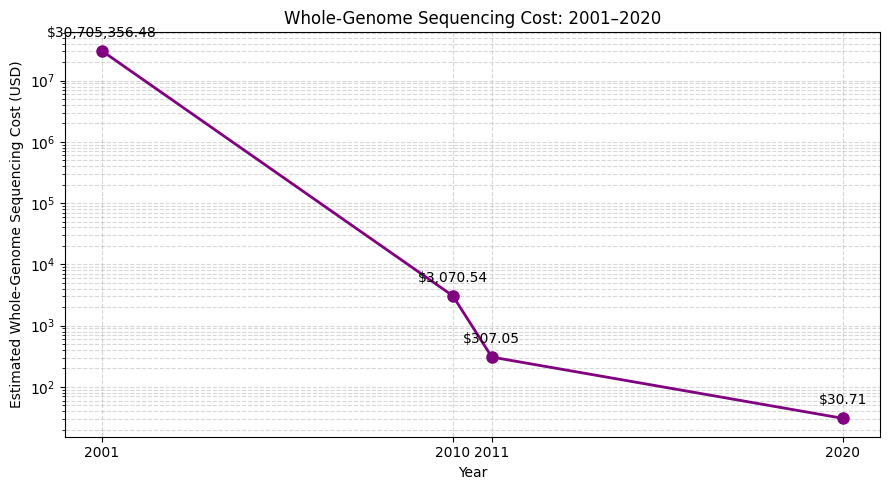

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

x = np.linspace(-10, 10, 200)

plt.figure(figsize=(8, 5))
plt.plot(x, x**2, color="blue", label="y = x²")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Plot of One Function")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))
plt.plot(x, x**2, color="blue", label="y = x²")
plt.plot(x, 2*x + 3, color="red", label="y = 2x + 3")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Plot of Two Functions")
plt.legend()
plt.grid(True)
plt.show()


url = (
    "https://raw.githubusercontent.com/"
    "yongmeiwang/AI_BigData_CancerBiology/main/"
    "Data/chrosome_basepairs.xlsx"
)

df = pd.read_excel(url)

print("Excel DataFrame:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())



numeric_columns = df.select_dtypes(include="number").columns.tolist()

if len(numeric_columns) == 1:
    basepair_column = numeric_columns[0]
else:
    print("\nNumeric columns:", numeric_columns)
    basepair_column = "basepairs"

basepairs = pd.to_numeric(
    df[basepair_column], errors="coerce"
).dropna()

total_basepairs = basepairs.sum()

angstrom_per_basepair = 3.4
meters_per_angstrom = 1e-10

total_length_meters = (
    total_basepairs
    * angstrom_per_basepair
    * meters_per_angstrom
)

total_mbp = total_basepairs / 1e6

print("\nGENOME SIZE RESULTS")
print(f"Total base pairs: {total_basepairs:,.0f}")
print(f"Total genome size: {total_mbp:,.2f} Mbp")
print(f"Total DNA length: {total_length_meters:.4f} meters")


years = [2001, 2010, 2011, 2020]

cost_per_mbp = [10000, 1.00, 0.10, 0.01]

total_costs = [
    total_mbp * rate for rate in cost_per_mbp
]

cost_df = pd.DataFrame({
    "Year": years,
    "Cost_per_Mbp_USD": cost_per_mbp,
    "Total_Genome_Cost_USD": total_costs
})

print("\nWHOLE-GENOME SEQUENCING COSTS")
display(cost_df.round(2))


plt.figure(figsize=(9, 5))

plt.plot(
    years,
    total_costs,
    marker="o",
    color="purple",
    linewidth=2,
    markersize=8
)

plt.yscale("log")
plt.xticks(years)
plt.xlabel("Year")
plt.ylabel("Estimated Whole-Genome Sequencing Cost (USD)")
plt.title("Whole-Genome Sequencing Cost: 2001–2020")
plt.grid(True, which="both", linestyle="--", alpha=0.5)

for year, cost in zip(years, total_costs):
    plt.annotate(
        f"${cost:,.2f}",
        (year, cost),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center"
    )

plt.tight_layout()
plt.show()